
# Deep Learning Assignment 4 – CO4


This notebook implements the experiments and calculations required in Q1–Q7

## 0. Setup and imports

In [1]:

import os, zipfile, itertools, warnings, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA, DictionaryLearning
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import mean_squared_error
from scipy.optimize import linear_sum_assignment

SEED = 42
rng = np.random.default_rng(SEED)
OUT = "/content/Assignment4_CO4_Results"
os.makedirs(OUT, exist_ok=True)

def save_table(df, name):
    path = os.path.join(OUT, name + ".csv")
    df.to_csv(path, index=False)
    print("Saved:", path)
    display(df)

def save_fig(name):
    path = os.path.join(OUT, name + ".png")
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

print("Output folder:", OUT)


Output folder: /content/Assignment4_CO4_Results



# Q1 – PCA and Probabilistic PCA (6 marks)

Wine dataset has 13 measurements and three target classes. The data are standardised before PCA. The notebook plots individual and cumulative explained variance, marks the component count reaching at least 90%, visualises the first two components by class, and reconstructs the standardised data with 2, 4, 6 and 8 components.

PPCA model from the assignment: **x = Wz + μ + ε**. Here x is the 13-dimensional observed wine measurement vector, z is a lower-dimensional latent vector, W maps latent variables to the observed feature space, μ is the mean vector, and ε is observation noise. A standard PPCA model assumes isotropic (same variance in every feature direction) Gaussian noise. One advantage of probabilistic formulation is that it provides a likelihood-based model and can support principled treatment of uncertainty or missing observations.


In [2]:

wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Classes:", np.unique(y))


Dataset shape: (178, 13)
Number of features: 13
Classes: [0 1 2]


Saved: /content/Assignment4_CO4_Results/Q1_explained_variance.csv


,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.361988,0.361988
1,2,0.192075,0.554063
2,3,0.111236,0.665300
3,4,0.070690,0.735990
4,5,0.065633,0.801623
5,6,0.049358,0.850981
6,7,0.042387,0.893368
7,8,0.026807,0.920175
8,9,0.022222,0.942397
9,10,0.019300,0.961697


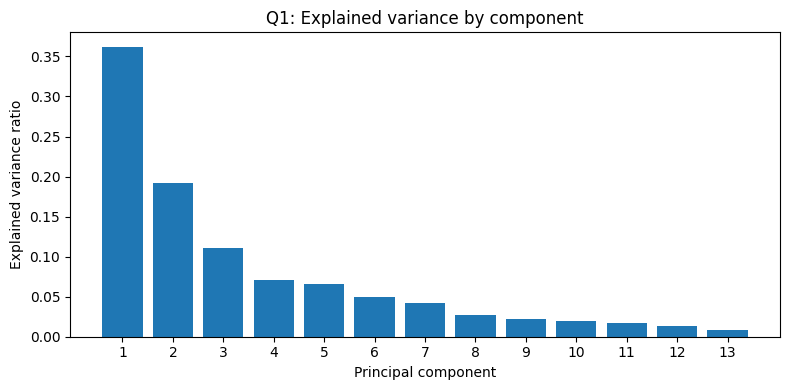

Saved: /content/Assignment4_CO4_Results/Q1_explained_variance_plot.png


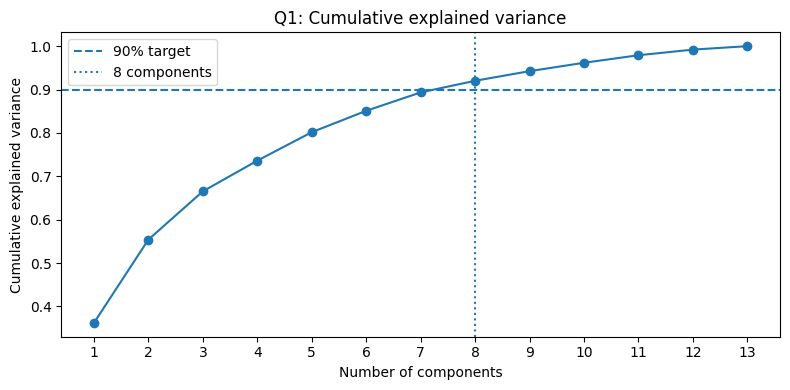

Saved: /content/Assignment4_CO4_Results/Q1_cumulative_variance.png
Components required for at least 90% variance: 8


In [3]:

pca_full = PCA()
Z_full = pca_full.fit_transform(X_std)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
n90 = int(np.argmax(cum_evr >= 0.90) + 1)

q1_var = pd.DataFrame({
    "component": np.arange(1, len(evr)+1),
    "explained_variance_ratio": evr,
    "cumulative_explained_variance": cum_evr
})
save_table(q1_var, "Q1_explained_variance")

plt.figure(figsize=(8,4))
plt.bar(np.arange(1,14), evr)
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.title("Q1: Explained variance by component"); plt.xticks(range(1,14))
save_fig("Q1_explained_variance_plot")

plt.figure(figsize=(8,4))
plt.plot(np.arange(1,14), cum_evr, marker="o")
plt.axhline(.90, linestyle="--", label="90% target")
plt.axvline(n90, linestyle=":", label=f"{n90} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("Q1: Cumulative explained variance"); plt.xticks(range(1,14)); plt.legend()
save_fig("Q1_cumulative_variance")

print(f"Components required for at least 90% variance: {n90}")


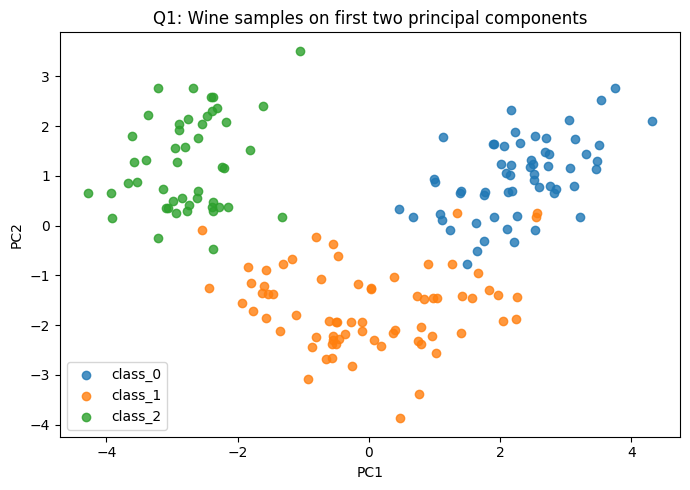

Saved: /content/Assignment4_CO4_Results/Q1_first_two_components_by_class.png


In [4]:

plt.figure(figsize=(7,5))
for cls, label in enumerate(wine.target_names):
    mask = (y == cls)
    plt.scatter(Z_full[mask,0], Z_full[mask,1], label=label, alpha=.8)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Q1: Wine samples on first two principal components")
plt.legend()
save_fig("Q1_first_two_components_by_class")


Saved: /content/Assignment4_CO4_Results/Q1_reconstruction_errors.csv


,components,reconstruction_MSE,reconstruction_RMSE,retained_variance
0,2,0.445937,0.667785,0.554063
1,4,0.264010,0.513819,0.735990
2,6,0.149019,0.386030,0.850981
3,8,0.079825,0.282532,0.920175


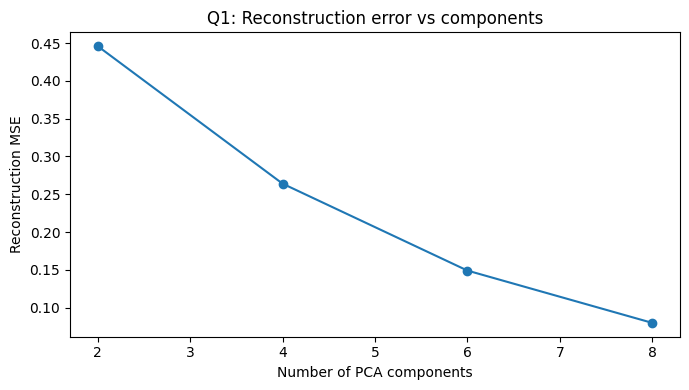

Saved: /content/Assignment4_CO4_Results/Q1_reconstruction_error_plot.png
Prediction before viewing results: adding components should not increase PCA reconstruction error.
Information lost with few components: low-variance directions and feature-specific detail not represented by retained components.


In [5]:

# Reconstruction using 2, 4, 6 and 8 principal components.
q1_recon_rows = []
for k in [2,4,6,8]:
    model = PCA(n_components=k)
    scores = model.fit_transform(X_std)
    X_rec = model.inverse_transform(scores)
    mse = mean_squared_error(X_std, X_rec)
    rmse = np.sqrt(mse)
    q1_recon_rows.append({"components": k, "reconstruction_MSE": mse, "reconstruction_RMSE": rmse,
                          "retained_variance": model.explained_variance_ratio_.sum()})
q1_recon = pd.DataFrame(q1_recon_rows)
save_table(q1_recon, "Q1_reconstruction_errors")

plt.figure(figsize=(7,4))
plt.plot(q1_recon.components, q1_recon.reconstruction_MSE, marker="o")
plt.xlabel("Number of PCA components"); plt.ylabel("Reconstruction MSE")
plt.title("Q1: Reconstruction error vs components")
save_fig("Q1_reconstruction_error_plot")

print("Prediction before viewing results: adding components should not increase PCA reconstruction error.")
print("Information lost with few components: low-variance directions and feature-specific detail not represented by retained components.")



# Q2 – Factor Analysis and Noisy Sensors

This section starts from the standardised Wine data and adds strong Gaussian noise to two selected features. PCA and Factor Analysis are fitted with two components. Factor Analysis estimates a separate residual/noise variance for each feature using `noise_variance_`. Because of sampling and feature correlations, verify whether the two selected noisy features actually have the largest estimates rather than assuming they must.


Saved: /content/Assignment4_CO4_Results/Q2_noise_variance_and_loadings.csv


,feature,added_noise,FA_estimated_noise_variance,PCA_first_component_loading,FA_first_component_loading,FA_noise_rank_1_is_largest
0,alcohol,True,1.105220,0.967884,-1.501707,2.0
1,malic_acid,False,0.813226,0.020187,-0.429853,6.0
2,ash,False,0.989749,0.004719,0.082194,3.0
3,alcalinity_of_ash,False,0.857177,-0.011556,-0.343021,5.0
4,magnesium,False,0.937868,0.027744,0.174081,4.0
5,total_phenols,False,0.216813,-0.008287,0.844977,12.0
6,flavanoids,False,0.048872,-0.022864,0.948762,13.0
7,nonflavanoid_phenols,False,0.692618,0.013778,-0.540253,8.0
8,proanthocyanins,False,0.547887,0.006191,0.623730,10.0
9,color_intensity,True,19.752518,0.242388,-0.875686,1.0


Noisy features: ['alcohol', 'color_intensity']
Top estimated FA noise features:


,feature,added_noise,FA_estimated_noise_variance,PCA_first_component_loading,FA_first_component_loading,FA_noise_rank_1_is_largest
9,color_intensity,True,19.752518,0.242388,-0.875686,1.0
0,alcohol,True,1.105220,0.967884,-1.501707,2.0
2,ash,False,0.989749,0.004719,0.082194,3.0
4,magnesium,False,0.937868,0.027744,0.174081,4.0
3,alcalinity_of_ash,False,0.857177,-0.011556,-0.343021,5.0


Do both injected noisy features rank in the top two? True


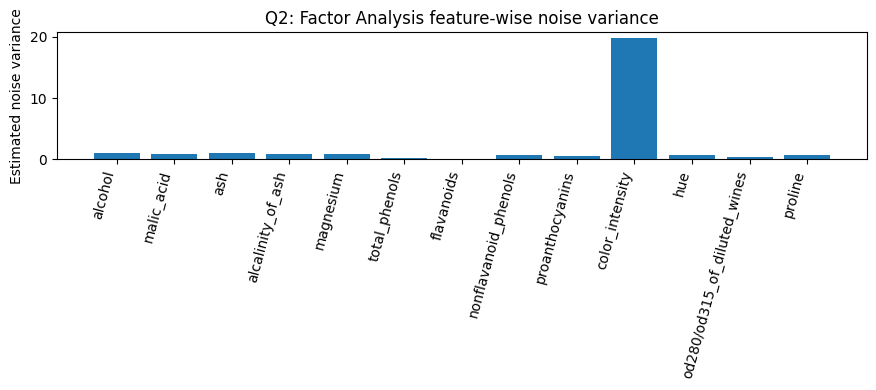

Saved: /content/Assignment4_CO4_Results/Q2_factor_analysis_noise_variance.png


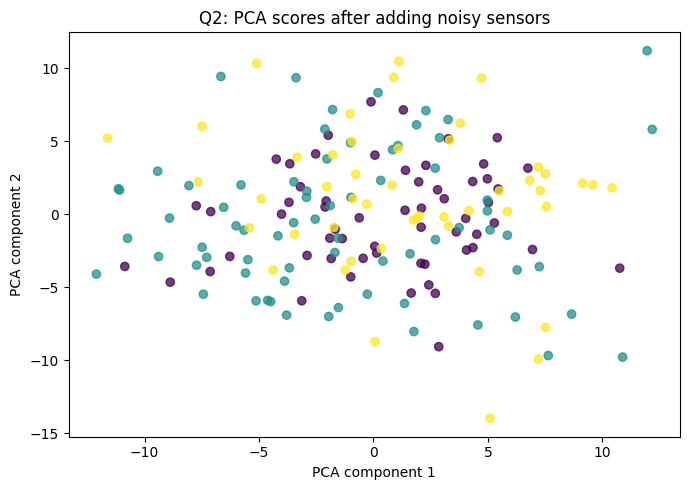

Saved: /content/Assignment4_CO4_Results/Q2_noisy_data_pca_scores.png
Model explanation: PPCA uses a common isotropic noise variance; Factor Analysis estimates a separate noise variance for each observed feature.
Prediction: Factor Analysis is expected to model unequal sensor reliability more flexibly. Interpret the actual estimated variances and loadings from the table.


In [6]:

# Reproducible noise injection into two features.
noise_features = [0, 9]  # alcohol and color_intensity in the sklearn Wine feature list
noise_sd = 5.0
rng_q2 = np.random.default_rng(SEED)
X_noisy = X_std.copy()
noise_added = rng_q2.normal(0, noise_sd, size=(X_noisy.shape[0], len(noise_features)))
X_noisy[:, noise_features] += noise_added

q2_fa = FactorAnalysis(n_components=2, random_state=SEED)
q2_fa_scores = q2_fa.fit_transform(X_noisy)
q2_pca = PCA(n_components=2, random_state=SEED)
q2_pca_scores = q2_pca.fit_transform(X_noisy)

q2_table = pd.DataFrame({
    "feature": feature_names,
    "added_noise": [i in noise_features for i in range(len(feature_names))],
    "FA_estimated_noise_variance": q2_fa.noise_variance_,
    "PCA_first_component_loading": q2_pca.components_[0],
    "FA_first_component_loading": q2_fa.components_[0]
})
q2_table["FA_noise_rank_1_is_largest"] = q2_table.FA_estimated_noise_variance.rank(ascending=False, method="min")
save_table(q2_table, "Q2_noise_variance_and_loadings")

print("Noisy features:", [feature_names[i] for i in noise_features])
print("Top estimated FA noise features:")
display(q2_table.sort_values("FA_estimated_noise_variance", ascending=False).head(5))
print("Do both injected noisy features rank in the top two?",
      set(q2_table.sort_values("FA_estimated_noise_variance", ascending=False).head(2).feature)
      == {feature_names[i] for i in noise_features})

plt.figure(figsize=(9,4))
plt.bar(feature_names, q2_fa.noise_variance_)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Estimated noise variance")
plt.title("Q2: Factor Analysis feature-wise noise variance")
save_fig("Q2_factor_analysis_noise_variance")

plt.figure(figsize=(7,5))
plt.scatter(q2_pca_scores[:,0], q2_pca_scores[:,1], c=y, cmap="viridis", alpha=.75)
plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2")
plt.title("Q2: PCA scores after adding noisy sensors")
save_fig("Q2_noisy_data_pca_scores")

print("Model explanation: PPCA uses a common isotropic noise variance; Factor Analysis estimates a separate noise variance for each observed feature.")
print("Prediction: Factor Analysis is expected to model unequal sensor reliability more flexibly. Interpret the actual estimated variances and loadings from the table.")



# Q3 – Independent Component Analysis (ICA)

Two source signals are generated: a sine wave and a square wave. They are mixed with two different invertible 2×2 mixing matrices. PCA and FastICA are used to recover components. Correlations are calculated between each recovered component and each original source. Because ICA component order and sign are arbitrary, the comparison uses absolute correlations and the best one-to-one assignment.


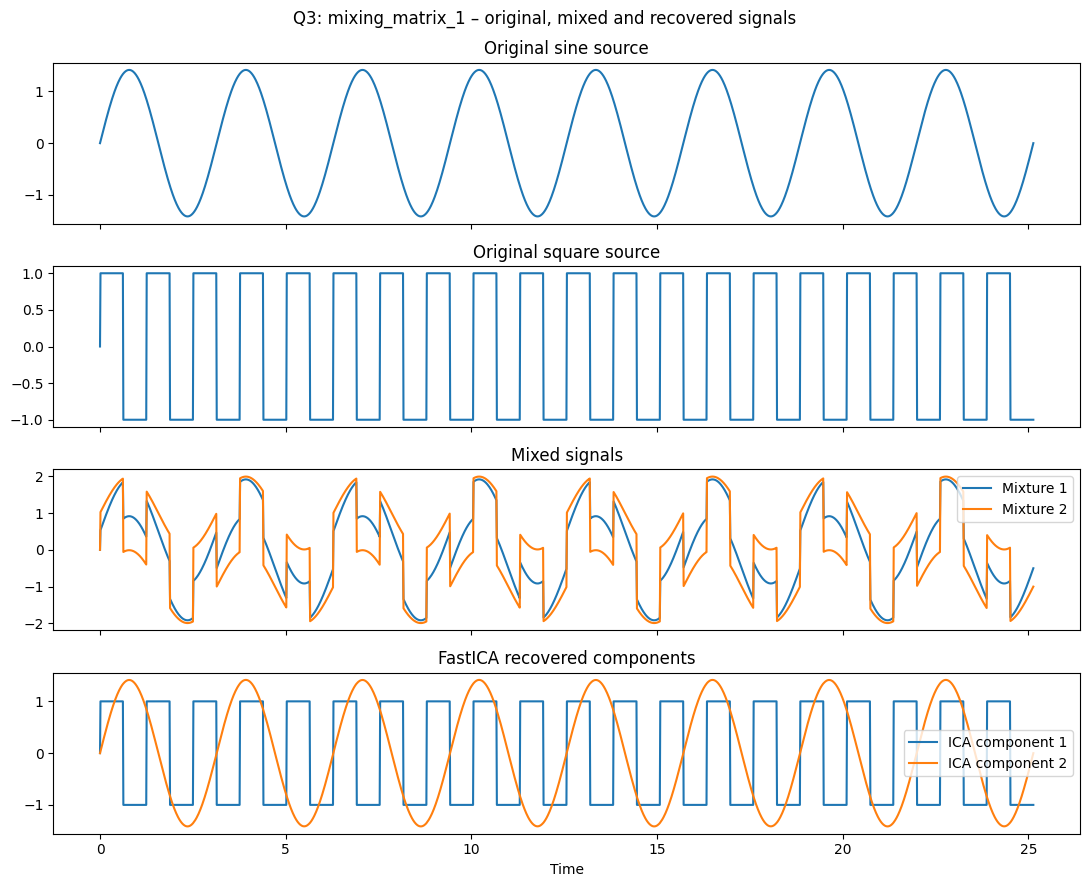

Saved: /content/Assignment4_CO4_Results/Q3_mixing_matrix_1_signals.png


/tmp/ipykernel_19020/2186446091.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


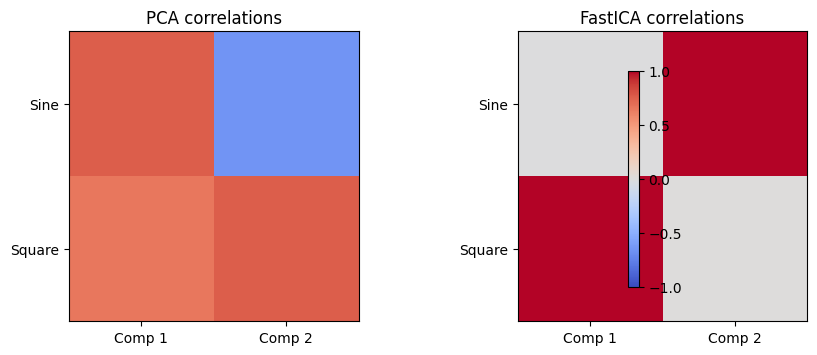

Saved: /content/Assignment4_CO4_Results/Q3_mixing_matrix_1_correlation_heatmaps.png


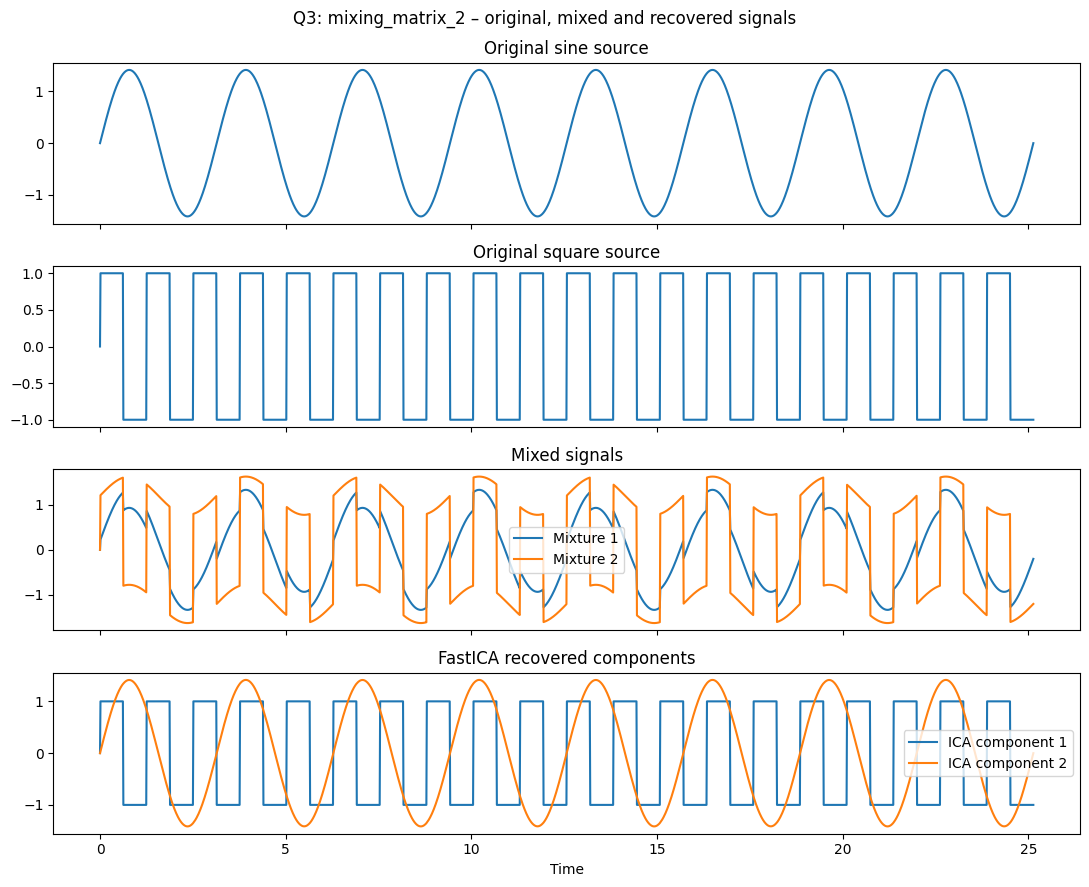

Saved: /content/Assignment4_CO4_Results/Q3_mixing_matrix_2_signals.png


/tmp/ipykernel_19020/2186446091.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


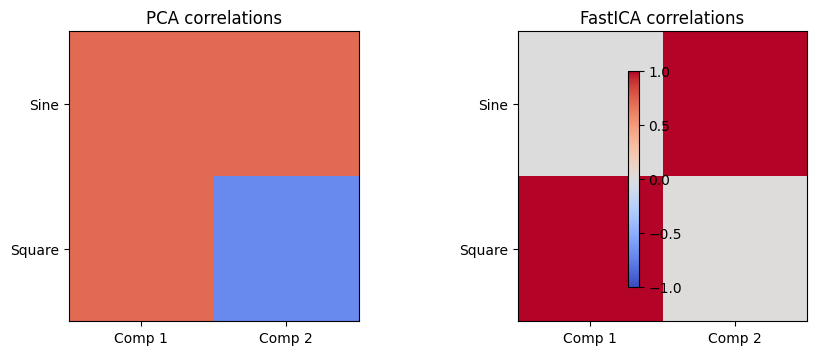

Saved: /content/Assignment4_CO4_Results/Q3_mixing_matrix_2_correlation_heatmaps.png
Saved: /content/Assignment4_CO4_Results/Q3_PCA_vs_ICA_correlations.csv


,case,method,original_source,recovered_component,correlation,absolute_correlation
0,mixing_matrix_1,PCA,1.0,1.0,0.757002,0.757002
1,mixing_matrix_1,PCA,2.0,2.0,0.757338,0.757338
2,mixing_matrix_1,FastICA,1.0,2.0,1.000000,1.000000
3,mixing_matrix_1,FastICA,2.0,1.0,1.000000,1.000000
4,mixing_matrix_2,PCA,1.0,1.0,0.706925,0.706925
5,mixing_matrix_2,PCA,2.0,2.0,-0.707289,0.707289
6,mixing_matrix_2,FastICA,1.0,2.0,1.000000,1.000000
7,mixing_matrix_2,FastICA,2.0,1.0,1.000000,1.000000


Mixing matrix 1 determinant: 0.65
Mixing matrix 2 determinant: 0.9
ICA source assumptions: sources are statistically independent and, for at most one Gaussian source, non-Gaussian.
PCA decorrelates components but does not generally make them statistically independent.
ICA signs and component order are arbitrary; compare using absolute correlations and best matching.


In [7]:

def make_sources(n=2000, seed=SEED):
    t = np.linspace(0, 8*np.pi, n)
    s1 = np.sin(2*t)  # sine source
    s2 = np.sign(np.sin(5*t))  # square source
    S = np.column_stack([s1, s2])
    S = StandardScaler().fit_transform(S)
    return t, S

def best_abs_correlations(S, recovered):
    corr = np.corrcoef(np.column_stack([S, recovered]).T)[:2, 2:]
    row_ind, col_ind = linear_sum_assignment(-np.abs(corr))
    matched = [{"original_source": int(i+1), "recovered_component": int(j+1),
                "correlation": corr[i,j], "absolute_correlation": abs(corr[i,j])}
               for i,j in zip(row_ind,col_ind)]
    return corr, pd.DataFrame(matched)

def run_ica_case(A, case_name):
    t, S = make_sources()
    Xmix = S @ A.T
    Xmix_std = StandardScaler().fit_transform(Xmix)

    pca = PCA(n_components=2, random_state=SEED)
    S_pca = pca.fit_transform(Xmix_std)

    ica = FastICA(n_components=2, whiten="unit-variance", random_state=SEED,
                  max_iter=2000, tol=1e-4)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        S_ica = ica.fit_transform(Xmix_std)

    corr_pca, match_pca = best_abs_correlations(S, S_pca)
    corr_ica, match_ica = best_abs_correlations(S, S_ica)

    rows=[]
    for method, corr, matched in [("PCA",corr_pca,match_pca),("FastICA",corr_ica,match_ica)]:
        for _,r in matched.iterrows():
            rows.append({"case":case_name,"method":method,**r.to_dict()})
    corr_df=pd.DataFrame(rows)

    fig,axs=plt.subplots(4,1,figsize=(11,9),sharex=True)
    axs[0].plot(t,S[:,0]); axs[0].set_title("Original sine source")
    axs[1].plot(t,S[:,1]); axs[1].set_title("Original square source")
    axs[2].plot(t,Xmix[:,0],label="Mixture 1"); axs[2].plot(t,Xmix[:,1],label="Mixture 2"); axs[2].legend(); axs[2].set_title("Mixed signals")
    axs[3].plot(t,S_ica[:,0],label="ICA component 1"); axs[3].plot(t,S_ica[:,1],label="ICA component 2"); axs[3].legend(); axs[3].set_title("FastICA recovered components")
    axs[3].set_xlabel("Time")
    plt.suptitle(f"Q3: {case_name} – original, mixed and recovered signals")
    save_fig(f"Q3_{case_name}_signals")

    fig,axs=plt.subplots(1,2,figsize=(9,3.5))
    im0=axs[0].imshow(corr_pca,vmin=-1,vmax=1,cmap="coolwarm"); axs[0].set_title("PCA correlations")
    im1=axs[1].imshow(corr_ica,vmin=-1,vmax=1,cmap="coolwarm"); axs[1].set_title("FastICA correlations")
    for ax in axs:
        ax.set_xticks([0,1],["Comp 1","Comp 2"]); ax.set_yticks([0,1],["Sine","Square"])
    fig.colorbar(im1,ax=axs.ravel().tolist(),shrink=.8)
    save_fig(f"Q3_{case_name}_correlation_heatmaps")
    return corr_df, corr_pca, corr_ica

A1=np.array([[1.0,.5],[.7,1.0]])
A2=np.array([[.8,.2],[.3,1.2]])
q3a, q3_pca_corr1, q3_ica_corr1 = run_ica_case(A1,"mixing_matrix_1")
q3b, q3_pca_corr2, q3_ica_corr2 = run_ica_case(A2,"mixing_matrix_2")
q3_results=pd.concat([q3a,q3b],ignore_index=True)
save_table(q3_results,"Q3_PCA_vs_ICA_correlations")
print("Mixing matrix 1 determinant:", np.linalg.det(A1))
print("Mixing matrix 2 determinant:", np.linalg.det(A2))
print("ICA source assumptions: sources are statistically independent and, for at most one Gaussian source, non-Gaussian.")
print("PCA decorrelates components but does not generally make them statistically independent.")
print("ICA signs and component order are arbitrary; compare using absolute correlations and best matching.")



# Q4 – Sparse Coding of Small Images

The scikit-learn Digits dataset contains 8×8 images represented by 64 pixel values. A dictionary with 36 atoms is learned. The sparse codes are computed for alpha (λ) values 0.1, 1 and 5. The notebook reports average non-zero coefficients per image, reconstruction MSE and displays learned atoms and example reconstructions.


In [8]:

digits = load_digits()
X_digits = digits.data.astype(float) / 16.0
print("Digits data shape:", X_digits.shape, "(samples, 64 pixels)")


Digits data shape: (1797, 64) (samples, 64 pixels)


Training dictionary with alpha = 0.1
Training dictionary with alpha = 1.0
Training dictionary with alpha = 5.0
Saved: /content/Assignment4_CO4_Results/Q4_sparse_coding_results.csv


,lambda_alpha,average_nonzero_coefficients_per_image,reconstruction_MSE,reconstruction_RMSE
0,0.1,15.573178,0.006410,0.080059
1,1.0,2.740679,0.035904,0.189484
2,5.0,0.000000,0.234597,0.484352


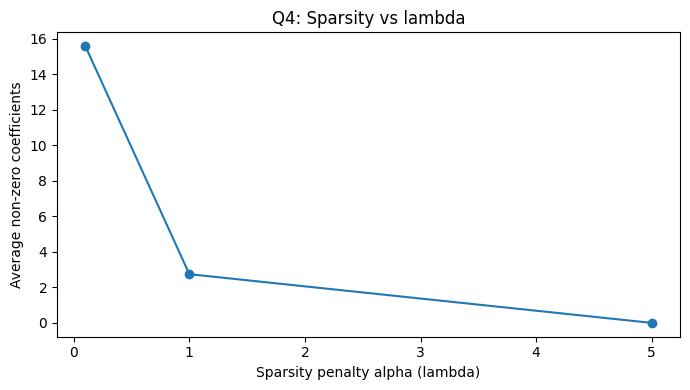

Saved: /content/Assignment4_CO4_Results/Q4_nonzero_vs_lambda.png


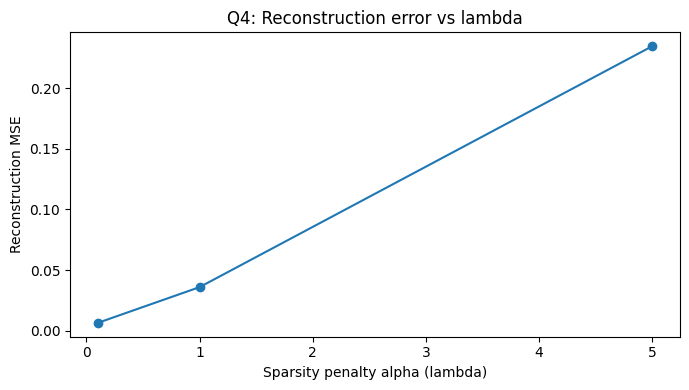

Saved: /content/Assignment4_CO4_Results/Q4_error_vs_lambda.png


In [9]:

q4_rows=[]
q4_models={}
q4_examples={}
for alpha in [0.1, 1.0, 5.0]:
    print("Training dictionary with alpha =", alpha)
    dl = DictionaryLearning(
        n_components=36, alpha=alpha, max_iter=250,
        fit_algorithm="lars", transform_algorithm="lasso_lars",
        random_state=SEED, n_jobs=-1
    )
    codes = dl.fit_transform(X_digits)
    X_reconstructed = codes @ dl.components_
    nonzero_per_image = np.count_nonzero(np.abs(codes)>1e-8, axis=1)
    mse = mean_squared_error(X_digits, X_reconstructed)
    q4_rows.append({
        "lambda_alpha": alpha,
        "average_nonzero_coefficients_per_image": nonzero_per_image.mean(),
        "reconstruction_MSE": mse,
        "reconstruction_RMSE": np.sqrt(mse)
    })
    q4_models[alpha]=dl
    q4_examples[alpha]=(codes,X_reconstructed,nonzero_per_image)

q4_results=pd.DataFrame(q4_rows)
save_table(q4_results,"Q4_sparse_coding_results")

plt.figure(figsize=(7,4))
plt.plot(q4_results.lambda_alpha,q4_results.average_nonzero_coefficients_per_image,marker="o")
plt.xlabel("Sparsity penalty alpha (lambda)"); plt.ylabel("Average non-zero coefficients")
plt.title("Q4: Sparsity vs lambda")
save_fig("Q4_nonzero_vs_lambda")

plt.figure(figsize=(7,4))
plt.plot(q4_results.lambda_alpha,q4_results.reconstruction_MSE,marker="o")
plt.xlabel("Sparsity penalty alpha (lambda)"); plt.ylabel("Reconstruction MSE")
plt.title("Q4: Reconstruction error vs lambda")
save_fig("Q4_error_vs_lambda")


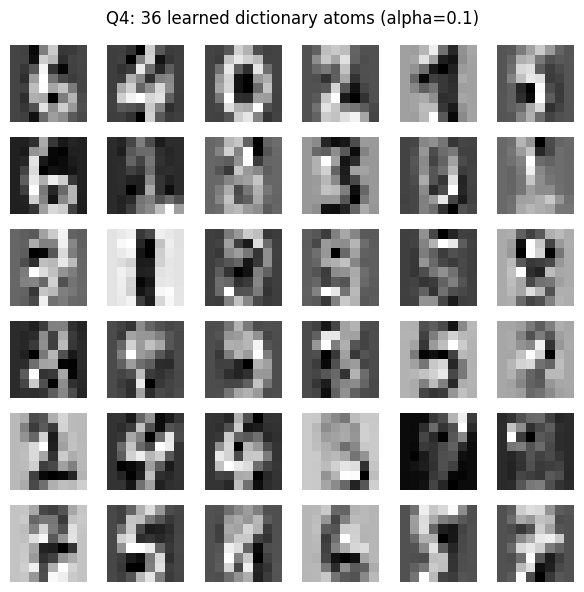

Saved: /content/Assignment4_CO4_Results/Q4_dictionary_atoms_alpha_0.1.png


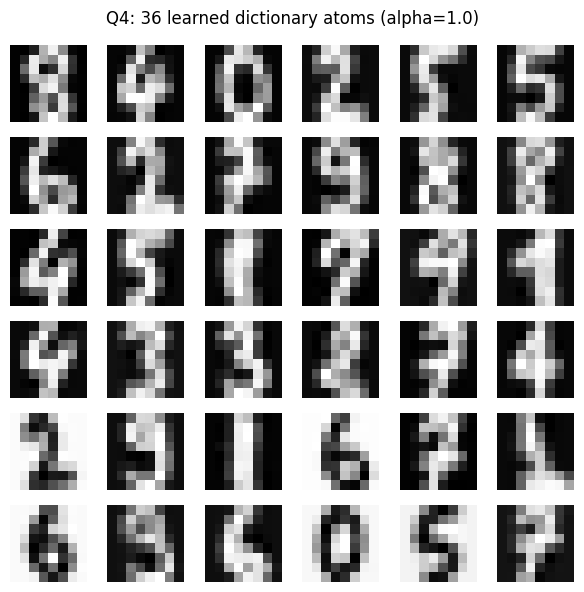

Saved: /content/Assignment4_CO4_Results/Q4_dictionary_atoms_alpha_1.0.png


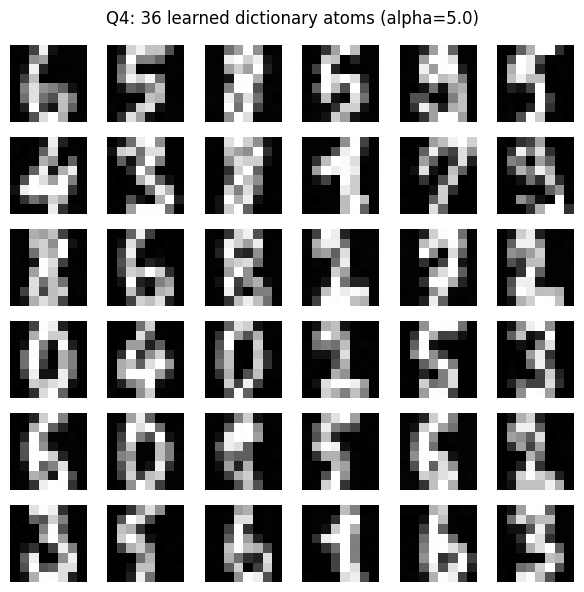

Saved: /content/Assignment4_CO4_Results/Q4_dictionary_atoms_alpha_5.0.png


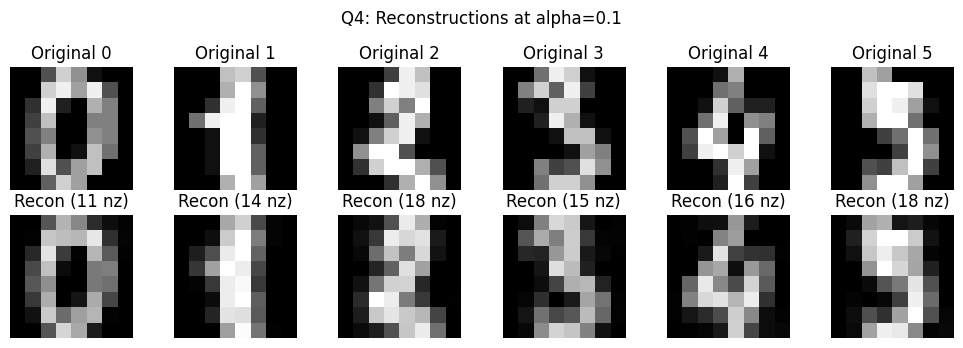

Saved: /content/Assignment4_CO4_Results/Q4_reconstructions_alpha_0.1.png


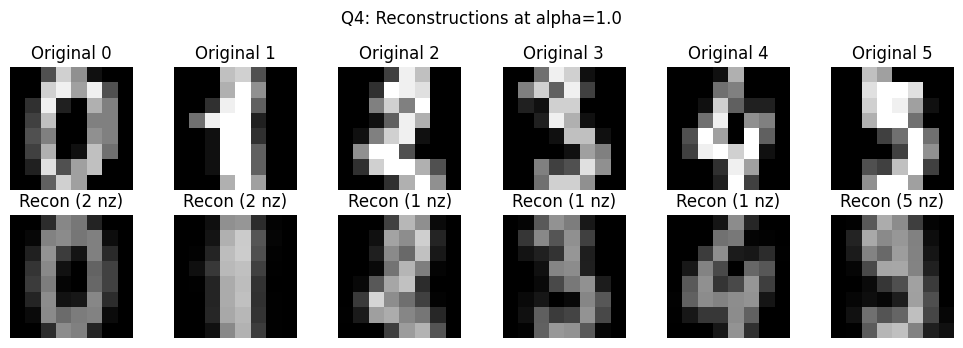

Saved: /content/Assignment4_CO4_Results/Q4_reconstructions_alpha_1.0.png


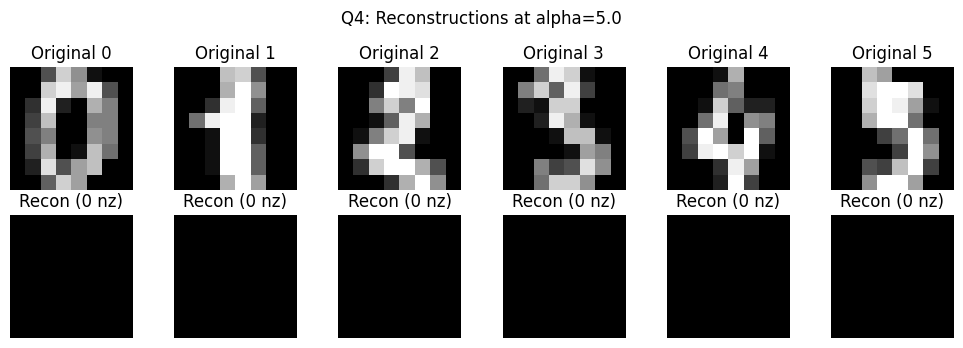

Saved: /content/Assignment4_CO4_Results/Q4_reconstructions_alpha_5.0.png
Prediction: as lambda/alpha increases, codes should generally become sparser (fewer non-zero coefficients), usually at the cost of larger reconstruction error.


In [10]:

# Display learned dictionary atoms for each alpha.
for alpha, model in q4_models.items():
    fig, axes = plt.subplots(6,6,figsize=(6,6))
    for i,ax in enumerate(axes.flat):
        ax.imshow(model.components_[i].reshape(8,8), cmap="gray")
        ax.axis("off")
    fig.suptitle(f"Q4: 36 learned dictionary atoms (alpha={alpha})")
    save_fig(f"Q4_dictionary_atoms_alpha_{alpha}")

# Display original and reconstructed examples for each alpha.
sample_ids=[0,1,2,3,4,5]
for alpha,(codes,Xrec,nnz) in q4_examples.items():
    fig,axes=plt.subplots(2,len(sample_ids),figsize=(10,3.5))
    for j,idx in enumerate(sample_ids):
        axes[0,j].imshow(X_digits[idx].reshape(8,8),cmap="gray",vmin=0,vmax=1)
        axes[0,j].set_title(f"Original {digits.target[idx]}")
        axes[1,j].imshow(np.clip(Xrec[idx].reshape(8,8),0,1),cmap="gray",vmin=0,vmax=1)
        axes[1,j].set_title(f"Recon ({nnz[idx]} nz)")
        axes[0,j].axis("off"); axes[1,j].axis("off")
    fig.suptitle(f"Q4: Reconstructions at alpha={alpha}")
    save_fig(f"Q4_reconstructions_alpha_{alpha}")

print("Prediction: as lambda/alpha increases, codes should generally become sparser (fewer non-zero coefficients), usually at the cost of larger reconstruction error.")



# Q5 – Bayesian Network for Examination-Portal Events

Graph: **P → U → S → C**.

The code calculates the full joint-table parameter count, Bayesian Network parameter count, exact joint probability P(P=1,U=1,S=1,C=1), and simulates 100, 1,000 and 10,000 days. The conditional estimates are calculated from simulated frequencies.


In [11]:

# Given probabilities from the assignment.
pP = 0.10
pU_given_P = {1:0.40, 0:0.02}
pS_given_U = {1:0.80, 0:0.05}
pC_given_S = {1:0.90, 0:0.05}

# Full joint table has 2^4 - 1 independent probabilities.
full_joint_parameters = 2**4 - 1
# BN: P prior (1) + U|P (2) + S|U (2) + C|S (2)
bn_parameters = 1 + 2 + 2 + 2
p_all_one = pP * pU_given_P[1] * pS_given_U[1] * pC_given_S[1]
print("Full joint table parameters:", full_joint_parameters)
print("Bayesian Network parameters:", bn_parameters)
print("P(P=1,U=1,S=1,C=1) =", p_all_one)


Full joint table parameters: 15
Bayesian Network parameters: 7
P(P=1,U=1,S=1,C=1) = 0.028800000000000006


In [12]:

def simulate_q5(n, seed=SEED):
    r=np.random.default_rng(seed)
    P=(r.random(n)<pP).astype(int)
    U=(r.random(n)<np.where(P==1,pU_given_P[1],pU_given_P[0])).astype(int)
    S=(r.random(n)<np.where(U==1,pS_given_U[1],pS_given_U[0])).astype(int)
    C=(r.random(n)<np.where(S==1,pC_given_S[1],pC_given_S[0])).astype(int)
    return pd.DataFrame({"P":P,"U":U,"S":S,"C":C})

q5_rows=[]
for n in [100,1000,10000]:
    sim=simulate_q5(n,SEED+n)
    est_u_p=sim.loc[sim.P==1,"U"].mean()
    est_c_s=sim.loc[sim.S==1,"C"].mean()
    q5_rows.append({"days":n,"estimated_P_U1_given_P1":est_u_p,
                    "given_P_U1_given_P1":.40,
                    "estimated_P_C1_given_S1":est_c_s,
                    "given_P_C1_given_S1":.90})
    if n==10000:
        sim_q5_10000=sim
q5_results=pd.DataFrame(q5_rows)
save_table(q5_results,"Q5_simulation_estimates")

print("Interpretation: estimates generally approach the given conditional probabilities as sample size grows, but random sampling causes variation and convergence is not guaranteed to be perfectly monotonic for every run.")


Saved: /content/Assignment4_CO4_Results/Q5_simulation_estimates.csv


,days,estimated_P_U1_given_P1,given_P_U1_given_P1,estimated_P_C1_given_S1,given_P_C1_given_S1
0,100,0.666667,0.4,1.000000,0.9
1,1000,0.387097,0.4,0.911392,0.9
2,10000,0.392675,0.4,0.902923,0.9


Interpretation: estimates generally approach the given conditional probabilities as sample size grows, but random sampling causes variation and convergence is not guaranteed to be perfectly monotonic for every run.



# Q6 – Probabilistic Modelling Mini-Investigations

## Part A: Linear Slow Feature Analysis (SFA)

Two channels are mixtures of a slow posture-like sine wave and a faster vibration-like sine wave. Slowness is measured as the average squared difference between consecutive samples. Linear SFA is implemented by centering and whitening the two channels, calculating the covariance matrix of consecutive differences, and selecting the eigenvector with the smallest eigenvalue.


Saved: /content/Assignment4_CO4_Results/Q6A_slowness_values.csv


,signal,slowness
0,Original slow signal,0.000012
1,Original fast vibration,0.007891
2,Mixed channel 1,0.004622
3,Mixed channel 2,0.009809
4,Extracted SFA feature,0.006079


Correlation extracted feature vs original slow signal: 0.9380717777669113


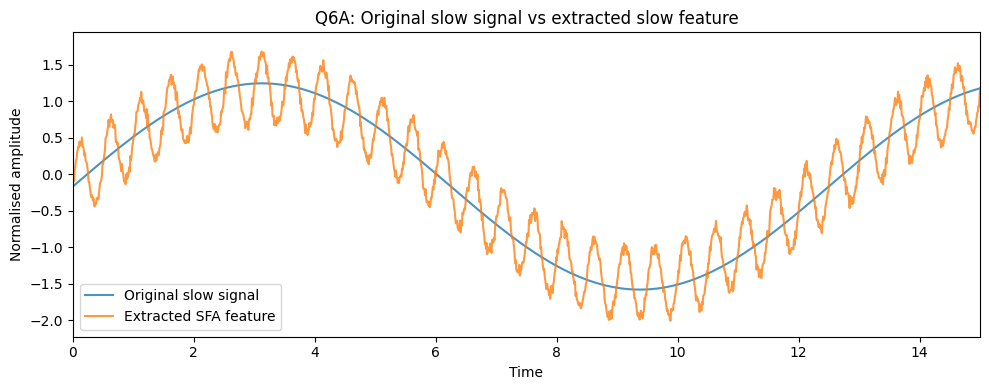

Saved: /content/Assignment4_CO4_Results/Q6A_sfa_extracted_feature.png


In [13]:

n=3000
t=np.linspace(0,30,n)
slow=np.sin(2*np.pi*0.08*t)
fast=np.sin(2*np.pi*2.0*t)
sources=np.column_stack([slow,fast])
A_sfa=np.array([[1.0,.6],[.4,1.0]])
X_channels=sources @ A_sfa.T + np.random.default_rng(SEED).normal(0,.03,(n,2))

def slowness(x):
    x=np.asarray(x)
    return np.mean(np.diff(x,axis=0)**2)

# Center and whiten using covariance eigendecomposition.
Xc=X_channels-X_channels.mean(axis=0)
cov=np.cov(Xc,rowvar=False)
eigvals,eigvecs=np.linalg.eigh(cov)
whitener=eigvecs @ np.diag(1/np.sqrt(np.maximum(eigvals,1e-12))) @ eigvecs.T
Xwhite=Xc @ whitener

dX=np.diff(Xwhite,axis=0)
diff_cov=np.cov(dX,rowvar=False)
evals,evecs=np.linalg.eigh(diff_cov)
w_slow=evecs[:,np.argmin(evals)]
sfa_feature=Xwhite @ w_slow

# Orient sign for visual comparison only (SFA sign is arbitrary).
if np.corrcoef(sfa_feature,slow)[0,1] < 0:
    sfa_feature=-sfa_feature
sfa_feature=(sfa_feature-sfa_feature.mean())/(sfa_feature.std()+1e-12)
slow_std=(slow-slow.mean())/(slow.std()+1e-12)

q6_sfa_table=pd.DataFrame([
    {"signal":"Original slow signal","slowness":slowness(slow)},
    {"signal":"Original fast vibration","slowness":slowness(fast)},
    {"signal":"Mixed channel 1","slowness":slowness(X_channels[:,0])},
    {"signal":"Mixed channel 2","slowness":slowness(X_channels[:,1])},
    {"signal":"Extracted SFA feature","slowness":slowness(sfa_feature)}
])
save_table(q6_sfa_table,"Q6A_slowness_values")
print("Correlation extracted feature vs original slow signal:", np.corrcoef(sfa_feature,slow_std)[0,1])

plt.figure(figsize=(10,4))
plt.plot(t,slow_std,label="Original slow signal",alpha=.8)
plt.plot(t,sfa_feature,label="Extracted SFA feature",alpha=.8)
plt.xlim(0,15); plt.xlabel("Time"); plt.ylabel("Normalised amplitude")
plt.title("Q6A: Original slow signal vs extracted slow feature"); plt.legend()
save_fig("Q6A_sfa_extracted_feature")



## Part B: Ancestral sampling and rejection sampling

Ancestral sampling follows the directed graph order: sample parent P first, then U conditional on P, then S conditional on U, then C conditional on S. This is necessary because a child's probability distribution depends on its parent value.


In [14]:

# Exact P(C=1) and P(P=1 | C=1) by summing over intermediate variables.
# P(C=1 | P=p) = sum_u P(u|p) sum_s P(s|u) P(C=1|s)
def p_c_given_p(p):
    total=0.0
    for u in [0,1]:
        pu=pU_given_P[u] if p==1 else (1-pU_given_P[0] if u==1 else 1-pU_given_P[1])
        # Explicit conditional probability P(U=u|P=p)
        pu = pU_given_P[p] if u==1 else 1-pU_given_P[p]
        for s in [0,1]:
            ps=pS_given_U[u] if s==1 else 1-pS_given_U[u]
            pc=pC_given_S[s] if s==1 else 1-pC_given_S[s]
            total += pu*ps*pc
    return total

pc_p1=p_c_given_p(1)
pc_p0=p_c_given_p(0)
pC_exact=pP*pc_p1+(1-pP)*pc_p0
pP_and_C=pP*pc_p1
pP_given_C_exact=pP_and_C/pC_exact

q6_sampling_rows=[]
for n in [100,1000,10000]:
    sim=simulate_q5(n,SEED+100+n)
    estimate=sim.C.mean()
    q6_sampling_rows.append({"samples":n,"estimated_P_C1":estimate,"exact_P_C1":pC_exact,
                             "absolute_error":abs(estimate-pC_exact)})
    if n==10000:
        sim_q6_10000=sim
        kept=sim[sim.C==1]
        rejected=sim[sim.C==0]
        p_p_given_c_est=kept.P.mean() if len(kept)>0 else np.nan

save_table(pd.DataFrame(q6_sampling_rows),"Q6B_ancestral_sampling_estimates")
print("Exact P(C=1):",pC_exact)
print("Exact P(P=1 | C=1):",pP_given_C_exact)
print("Estimated P(P=1 | C=1) from 10,000 samples:",p_p_given_c_est)
print("Samples kept (C=1):",len(kept))
print("Samples rejected (C=0):",len(rejected))


Saved: /content/Assignment4_CO4_Results/Q6B_ancestral_sampling_estimates.csv


,samples,estimated_P_C1,exact_P_C1,absolute_error
0,100,0.2000,0.945325,0.745325
1,1000,0.1310,0.945325,0.814325
2,10000,0.1312,0.945325,0.814125


Exact P(C=1): 0.945325
Exact P(P=1 | C=1): 0.09864332372464497
Estimated P(P=1 | C=1) from 10,000 samples: 0.2629573170731707
Samples kept (C=1): 1312
Samples rejected (C=0): 8688



# Q7 – Extend the Examination-Portal Model

**Alternative A:** Add G (generator failure) as a child of P; add W (Wi-Fi outage) as a child of S; let E (postponement) depend on G, W and C. This represents generator failure after a power cut, Wi-Fi failure associated with portal/network disruption, and postponement risk increasing when operational failures and complaints occur.

**Alternative B:** Add G as a child of P; add W as an independent infrastructure event; let E depend on G, W and S. This treats Wi-Fi outage as independent of server failure and uses server-down status directly rather than complaints.

For the final computational design, use Alternative A. The numerical probabilities below are explicit modelling assumptions chosen for this assignment, not supplied empirical facts. A CPT for E is specified for all 2³ combinations of G, W and C.


In [15]:

# Final DAG:
# P -> U -> S -> C
# P -> G
# S -> W
# G, W, C -> E

# Assumed probabilities for newly introduced events.
pG_given_P = {1:0.30, 0:0.01}
pW_given_S = {1:0.20, 0:0.03}

# P(E=1 | G,W,C), indexed by (G,W,C).
pE_given_GWC = {
    (0,0,0):0.01,
    (0,0,1):0.10,
    (0,1,0):0.35,
    (0,1,1):0.60,
    (1,0,0):0.40,
    (1,0,1):0.65,
    (1,1,0):0.80,
    (1,1,1):0.95
}

# Parameter count:
# P prior: 1
# U|P: 2; S|U: 2; C|S: 2; G|P: 2; W|S: 2; E|G,W,C: 2^3 = 8
bn7_parameters = 1+2+2+2+2+2+8
full_joint7_parameters = 2**7-1
print("Full joint table parameters:",full_joint7_parameters)
print("Final Bayesian Network parameters:",bn7_parameters)

# Probability table for each conditional variable.
q7_cpt = pd.DataFrame([
    ["P", "root", "P=1", pP],
    ["U", "P", "P=0", pU_given_P[0]],
    ["U", "P", "P=1", pU_given_P[1]],
    ["S", "U", "U=0", pS_given_U[0]],
    ["S", "U", "U=1", pS_given_U[1]],
    ["C", "S", "S=0", pC_given_S[0]],
    ["C", "S", "S=1", pC_given_S[1]],
    ["G", "P", "P=0", pG_given_P[0]],
    ["G", "P", "P=1", pG_given_P[1]],
    ["W", "S", "S=0", pW_given_S[0]],
    ["W", "S", "S=1", pW_given_S[1]],
] + [["E","G,W,C",f"G={g},W={w},C={c}",prob]
     for (g,w,c),prob in pE_given_GWC.items()],
    columns=["event","parent(s)","condition","probability_event_equals_1"])
save_table(q7_cpt,"Q7_conditional_probability_table")


Full joint table parameters: 127
Final Bayesian Network parameters: 19
Saved: /content/Assignment4_CO4_Results/Q7_conditional_probability_table.csv


,event,parent(s),condition,probability_event_equals_1
0,P,root,P=1,0.10
1,U,P,P=0,0.02
2,U,P,P=1,0.40
3,S,U,U=0,0.05
4,S,U,U=1,0.80
5,C,S,S=0,0.05
6,C,S,S=1,0.90
7,G,P,P=0,0.01
8,G,P,P=1,0.30
9,W,S,S=0,0.03


In [16]:

def simulate_q7(n,seed=SEED):
    r=np.random.default_rng(seed)
    P=(r.random(n)<pP).astype(int)
    U=(r.random(n)<np.where(P==1,pU_given_P[1],pU_given_P[0])).astype(int)
    S=(r.random(n)<np.where(U==1,pS_given_U[1],pS_given_U[0])).astype(int)
    C=(r.random(n)<np.where(S==1,pC_given_S[1],pC_given_S[0])).astype(int)
    G=(r.random(n)<np.where(P==1,pG_given_P[1],pG_given_P[0])).astype(int)
    W=(r.random(n)<np.where(S==1,pW_given_S[1],pW_given_S[0])).astype(int)
    pE=np.array([pE_given_GWC[(int(g),int(w),int(c))] for g,w,c in zip(G,W,C)])
    E=(r.random(n)<pE).astype(int)
    return pd.DataFrame({"P":P,"U":U,"S":S,"C":C,"G":G,"W":W,"E":E})

sim7=simulate_q7(10000,SEED+700)
pE_est=sim7.E.mean()
pE_given_P1_est=sim7.loc[sim7.P==1,"E"].mean()
q7_summary=pd.DataFrame([
    ["P(E=1)",pE_est],
    ["P(E=1 | P=1)",pE_given_P1_est],
    ["P(P=1)",sim7.P.mean()],
    ["P(E=1 | P=0)",sim7.loc[sim7.P==0,"E"].mean()]
],columns=["quantity","estimate"])
save_table(q7_summary,"Q7_simulation_results")

print("Simulation pseudocode:")
print("Sample P; sample U|P and S|U and C|S; sample G|P and W|S; sample E|G,W,C.")
print("Interpretation: compare P(E=1|P=1) with P(E=1). A larger conditional value indicates higher postponement risk on power-cut days in this assumed model.")


Saved: /content/Assignment4_CO4_Results/Q7_simulation_results.csv


,quantity,estimate
0,P(E=1),0.059400
1,P(E=1 | P=1),0.223261
2,P(P=1),0.096300
3,P(E=1 | P=0),0.041939


Simulation pseudocode:
Sample P; sample U|P and S|U and C|S; sample G|P and W|S; sample E|G,W,C.
Interpretation: compare P(E=1|P=1) with P(E=1). A larger conditional value indicates higher postponement risk on power-cut days in this assumed model.



## Q7 Stage 6 – Evaluation prompts

- A probability graph makes conditional dependencies explicit and can represent the joint distribution with fewer parameters than a full 7-variable table.
- A missing edge can incorrectly assert conditional independence; an unnecessary edge increases complexity and may fit noise.
- A wrong probability table gives biased risk estimates even if the graph structure is sensible.
- Bayesian Networks are useful when a system has understandable causal/dependency structure, uncertain events, and a need to calculate conditional risks.



# Final result export

The following cell zips all CSV tables and PNG graphs created in this notebook and downloads the ZIP directly to your computer. It does **not** save anything to Google Drive.


In [17]:

# Create a ZIP file locally in the Colab runtime and download to your PC.
from google.colab import files
zip_path="/content/Assignment4_CO4_Results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for root,dirs,files_list in os.walk(OUT):
        for filename in files_list:
            full=os.path.join(root,filename)
            zf.write(full,arcname=os.path.relpath(full,OUT))
print("ZIP created:",zip_path)
files.download(zip_path)


ZIP created: /content/Assignment4_CO4_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>